# ICS 3202: Artificial Intelligence — Semester Project
# Base Model: Multinomial Naive Bayes Transaction Categoriser

**Application:** Akiba — a personal-finance mobile application with an AI advisor that helps users
track and understand their spending.

**Repository:** `SemProject_MLEngine`

**What this notebook covers**

| Part | Content |
|---|---|
| **A** | ML approach and algorithms relevant to the dataset and expected output |
| **B** | Critical account of the data cleaning process, exploration → final modelling dataset |
| **C** | Exploratory Data Analysis with six derived observations |
| **D** | Modelling approach on the base model, with validity measures (grouped CV, hyper-parameter tuning, baselines, ablation) |
| **E** | Further validation — eight comparison models built through the identical process |
| **F** | Conclusions and recommended next steps |

> Every number, table and figure below is computed when the notebook runs. Nothing is hard-coded.

---
# From Deliverable 1 to Deliverable 2

Deliverable 1 (`Expenses_Exploration.ipynb`) explored `Expenses_clean.csv`, the Kaggle *Financial
Transactions Dataset (Expenses & Income)*: 938 rows of personal spending in BYN, with six columns —
`date_time`, `category`, `account`, `amount`, `currency`, `tags`.

That exploration produced the finding that shapes this deliverable: **the dataset has no description or
merchant text column.** Akiba's categoriser must map an M-Pesa description to a category, and rows that
carry only a date, an account, an amount and an already-assigned category offer no text-to-label
mapping to learn. Showing that a dataset cannot support the intended task is a valid result of
exploration, not a failure of it — it is precisely the question exploration exists to answer.

**The pivot.** With no real labelled data available — the app has no users yet — the project bootstraps
a training set from a hand-built merchant lexicon:

```
lexicon.json  →  generate.py  →  data/train.csv
```

`data/train.csv` is the dataset modelled in this notebook. The Kaggle data plays no part in training
the shipped model.

**What the Kaggle dataset is still good for.** Its dates, amounts and categories suit tasks that need no
description text — unsupervised clustering of spending behaviour, or forecasting monthly spend per
category. Both are candidates for a later deliverable. Section A.2 sets the two datasets side by side.

---
# Part A — ML Approach and Algorithm Identification

## A.1 What the application has to produce

A user's M-Pesa statement line arrives as free text plus a number:

```
"merchant payment to naivas westlands"   KES 1,240
```

The app must return **one expense category** out of nine, together with a confidence score so the UI
can decide whether to auto-apply the label or ask the user to confirm.

| Property | Value |
|---|---|
| **Input** | `description` (short free text) + `amount` (positive number, KES) |
| **Output** | One of 9 category labels + a probability per label |
| **Label set** | Food, Rent, Transport, Academic, Airtime & Data, Entertainment, Health, Personal Care, Other |
| **Labels available at training time?** | Yes — every training row carries its category |
| **Deployment constraint** | Model ships as a single JSON file and is executed in **pure TypeScript** inside the Express server — no Python service, no external API call |

## A.2 The two datasets in this project — and why only one can train this model

This is the most important structural point in the project, so it is stated first.

| | **Deliverable 1 dataset** | **Modelling dataset (this notebook)** |
|---|---|---|
| File | `Expenses_clean.csv` (Kaggle) | `data/train.csv` |
| Origin | Exported from a finance-tracking app | Generated by `generate.py` from `lexicon.json` |
| Rows | 938 | 5,587 |
| Columns | `date_time`, `category`, `account`, `amount`, `currency`, `tags` | `description`, `amount`, `category`, `keyword` |
| Currency | BYN (Belarusian rouble) | KES |
| **Has a text description column?** | **No** | **Yes** |

**The Kaggle dataset cannot train this model.** The task is to predict a category *from a transaction
description*, and that dataset has no description column at all. Its `category` field is already
populated, so there is no text-to-label mapping left to learn. It is also denominated in BYN with
Belarusian merchant behaviour, which does not transfer to Kenyan M-Pesa descriptions.

The Kaggle dataset remains useful for a **different** task — unsupervised clustering of spending
behaviour, or time-series forecasting of monthly spend per category — but not for this one. Those are
candidates for a later deliverable, not this model.

**Consequence:** the system has no real labelled data, so a *bootstrap* dataset was synthesised from a
hand-built merchant lexicon. Part B examines exactly what that costs us, and Part D measures it.

## A.3 Task type

| Question | Answer |
|---|---|
| Are labels available? | Yes → **supervised learning** |
| Is the target discrete or continuous? | Discrete, 9 values → **classification** |
| How many classes? | 9 → **multi-class** (not binary) |
| How many labels per row? | Exactly one → **single-label** |
| What is the dominant feature? | Short free text → **text classification** |

> **Identified approach: supervised, single-label, multi-class text classification.**

Clustering (K-Means) and regression are both ruled out — clustering because the labels already exist
and must match the app's fixed nine categories, regression because the target is categorical.

## A.4 Candidate algorithms

| Algorithm | Fit for this problem | Verdict |
|---|---|---|
| **Multinomial Naive Bayes** | Built for integer word counts; trains in milliseconds; parameters are a log-probability matrix that ports to TypeScript in a few lines | **Selected as base model** |
| Complement NB | NB variant designed for imbalanced text; same export story | Comparison |
| Logistic Regression + TF-IDF | Strong, well-calibrated linear text baseline; needs float weights + TF-IDF statistics at inference | Comparison |
| Linear SVC | Usually the strongest linear text classifier | Comparison — no native probabilities |
| SGD (hinge) | Same decision function, online-trainable for future user corrections | Comparison |
| Random Forest | Handles non-linearity, but weak on high-dimensional sparse text and large to serialise | Comparison |
| Character n-gram + LogReg | Matches sub-word morphology, so it can generalise to merchants never seen in training | Comparison |
| Transformer (BERT) | Highest ceiling, but hundreds of MB and impossible to run in the TypeScript runtime | Rejected on deployment constraint |

**Why Naive Bayes is the base model:** the deployment constraint is binding. The model must execute in
TypeScript with no Python runtime. A Naive Bayes model is a class-prior vector plus a
`(n_classes × n_features)` log-probability matrix — inference is one sparse dot product. It is the only
candidate that is simultaneously competitive on short text *and* trivial to port. Part E tests honestly
whether that choice costs accuracy.

---
# Part B — Data Cleaning: Exploration → Final Modelling Dataset

## B.0 Setup

In [1]:
import json, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linestyle": "-",
    "figure.facecolor": "white", "axes.facecolor": "white",
})

NAVY, BLUE, TEAL, AMBER, RED, GREY = "#1C3F63", "#2A6FA8", "#127A73", "#C8781A", "#C0564B", "#637586"
PALETTE = [BLUE, TEAL, AMBER, NAVY, RED, "#7E57A2", "#4C9A6A", "#B5852C", GREY]
HEAT = LinearSegmentedColormap.from_list("heat", ["#FFFFFF", "#CFE0EE", "#2A6FA8", "#1C3F63"])

def hboxplot(ax, data, tick_labels, **kw):
    """Horizontal boxplot that works across matplotlib versions.

    matplotlib >= 3.9 renamed `labels` to `tick_labels`; >= 3.10 replaced
    `vert=False` with `orientation="horizontal"`. Try the modern spelling,
    fall back to the legacy one.
    """
    try:
        bp = ax.boxplot(data, orientation="horizontal", **kw)
    except TypeError:
        bp = ax.boxplot(data, vert=False, **kw)
    ax.set_yticks(range(1, len(tick_labels) + 1))
    ax.set_yticklabels(tick_labels)
    return bp

# Locate data/train.csv whether the notebook runs at the repo root or elsewhere
CANDIDATES = [Path("data/train.csv"), Path("../data/train.csv"), Path("train.csv")]
TRAIN_CSV = next((p for p in CANDIDATES if p.exists()), None)
if TRAIN_CSV is None:
    raise FileNotFoundError(
        "data/train.csv not found. Run `python generate.py` at the repo root first, "
        "or upload data/train.csv if running in Colab."
    )
print("Loaded from:", TRAIN_CSV.resolve())

Loaded from: /home/claude/austineigunza/semproject_mlengine/data/train.csv


## B.1 Where the data comes from

There are no users yet, so there is no labelled history to learn from. `generate.py` bootstraps a
training set from `lexicon.json`, a hand-curated list of Kenyan merchants and keywords per category:

```
lexicon.json  →  generate.py  →  data/train.csv
```

For every keyword the generator emits rows of the form
`template.format(keyword, place)` with an amount sampled log-uniformly from a per-category range.

**The twelve templates are applied to every category**, so template words ("pay bill", "ltd",
"lipa na mpesa") carry no category signal by construction. Only the keyword does. B.6 verifies this
empirically rather than taking it on trust.

### Validation gates already enforced inside the generator

| Gate | What it prevents |
|---|---|
| `empty` check | A category in the lexicon with zero keywords → a class with no training rows |
| `unknown` check | A lexicon category with no amount range defined |
| `seen` map | The same keyword listed under two different categories → contradictory labels |
| `random.seed(42)` | Non-reproducible regeneration |
| `MIN_ROWS_PER_KEYWORD = 6` | A rare keyword appearing too few times to be learnable |

These are data-quality controls applied *before* the CSV exists — cleaning pushed upstream to the
source, which is cheaper than repairing the output afterwards.

## B.2 Structural checks on the raw file

In [2]:
raw = pd.read_csv(TRAIN_CSV)

print(f"Shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns\n")
print("Datatypes:"); print(raw.dtypes.to_string())
print("\nMissing values per column:"); print(raw.isnull().sum().to_string())
print(f"\nTotal missing: {int(raw.isnull().sum().sum())}")
raw.head(8)

Shape: 5,587 rows x 4 columns

Datatypes:
description      str
amount         int64
category         str
keyword          str

Missing values per column:
description    0
amount         0
category       0
keyword        0

Total missing: 0


,description,amount,category,keyword
0,faiba cbd,340,Airtime & Data,faiba
1,buy goods grocery,115,Food,grocery
2,customer transfer to pharmacy,2612,Health,pharmacy
3,merchant payment to cash thika road,65,Other,cash
4,pay bill online to pizza,171,Food,pizza
5,pay bill online to faras,611,Transport,faras
6,gym branch westlands,2110,Personal Care,gym
7,customer transfer to m shwari,59,Other,m shwari


In [3]:
checks = {
    "Exact duplicate rows (description+amount+category)": int(raw.duplicated(["description","amount","category"]).sum()),
    "Repeated description strings":                       int(raw.description.duplicated().sum()),
    "Descriptions mapped to >1 category (contradictory)": int((raw.groupby("description").category.nunique() > 1).sum()),
    "Non-positive amounts":                               int((raw.amount <= 0).sum()),
    "Blank / whitespace-only descriptions":               int(raw.description.astype(str).str.strip().eq("").sum()),
    "Rows with a missing group key (keyword)":            int(raw.keyword.isnull().sum()),
    "Distinct categories":                                int(raw.category.nunique()),
    "Distinct source keywords":                           int(raw.keyword.nunique()),
}
report = pd.DataFrame(checks.items(), columns=["Check", "Count"])
display(report)

print("\nInterpretation")
print("  - 0 missing values and 0 exact duplicates: the generator writes a clean file by construction.")
print(f"  - {checks['Repeated description strings']} repeated description STRINGS exist, but 0 of them map to")
print("    conflicting categories, so they are consistent restatements, not label noise.")
print("    They are kept: dropping them would silently reweight the classes.")
print("  - This is NOT evidence of a high-quality dataset. It is evidence of a synthetic one.")
print("    The real cleaning problem is distribution shift, not dirt. See B.7.")

,Check,Count
0,Exact duplicate rows (description+amount+categ...,0
1,Repeated description strings,202
2,Descriptions mapped to >1 category (contradict...,0
3,Non-positive amounts,0
4,Blank / whitespace-only descriptions,0
5,Rows with a missing group key (keyword),0
6,Distinct categories,9
7,Distinct source keywords,457



Interpretation
  - 0 missing values and 0 exact duplicates: the generator writes a clean file by construction.
  - 202 repeated description STRINGS exist, but 0 of them map to
    conflicting categories, so they are consistent restatements, not label noise.
    They are kept: dropping them would silently reweight the classes.
  - This is NOT evidence of a high-quality dataset. It is evidence of a synthetic one.
    The real cleaning problem is distribution shift, not dirt. See B.7.


## B.3 Cleaning step 1 — text normalisation

`features.py` defines the normalisation, and it is **binding on two codebases at once**: the identical
steps are reimplemented in the app's `server/src/modules/categoriser/text.ts`. The exported model is
only valid if Python and TypeScript build byte-identical tokens. A change on one side without the other
silently corrupts predictions in production — not a crash, just quietly wrong categories.

| Step | Operation | Reason |
|---|---|---|
| 1 | lowercase | `NAIVAS` and `Naivas` are the same merchant |
| 2 | replace every non `a-z`/whitespace character with a space | Removes receipt codes, phone digits, `&`, punctuation — high-cardinality noise that would never generalise |
| 3 | collapse repeated whitespace | Produces clean token boundaries |
| 4 | append one amount-bucket token | Injects magnitude as a categorical feature NB can consume |
| 5 | unigrams + bigrams | Bigrams capture `"java house"`, `"pay bill"` as single units |

Step 2 is the one with real consequences: it **destroys all digits**, which is why the amount has to be
re-introduced separately in step 4.

In [4]:
# Mirrors features.py exactly. Imported if available so the notebook cannot drift from the shipped code.
try:
    from features import clean, amount_bucket, to_document, vectorizer_kwargs
    print("Using features.py from the repository (single source of truth).")
except ImportError:
    print("features.py not importable — using the inline equivalent.")
    AMOUNT_BUCKETS = [(0,100,"amt_xs"), (100,500,"amt_s"), (500,2000,"amt_m"),
                      (2000,10000,"amt_l"), (10000,None,"amt_xl")]
    _NON_ALPHA, _SPACES = re.compile(r"[^a-z\s]+"), re.compile(r"\s+")

    def clean(text):
        text = "" if text is None else str(text)
        return _SPACES.sub(" ", _NON_ALPHA.sub(" ", text.lower())).strip()

    def amount_bucket(amount):
        v = abs(float(amount or 0))
        for low, high, tok in AMOUNT_BUCKETS:
            if high is None or v < high:
                return tok
        return AMOUNT_BUCKETS[-1][2]

    def to_document(description, amount):
        c = clean(description)
        b = amount_bucket(amount)
        return f"{c} {b}" if c else b

    def vectorizer_kwargs():
        return {"lowercase": False, "token_pattern": r"\S+", "ngram_range": (1, 2)}

demo = pd.DataFrame({
    "raw_description": ["Pay Bill to NAIVAS #4471", "ARTCAFFE LTD, Westlands",
                        "merchant payment to JAVA HOUSE", "UBER*TRIP 0712345678", "KPLC PREPAID TOKEN"],
    "amount": [1240, 85, 650, 320, 15000],
})
demo["after_clean()"]  = demo.raw_description.map(clean)
demo["amount_bucket()"] = demo.amount.map(amount_bucket)
demo["final_document"] = [to_document(d, a) for d, a in zip(demo.raw_description, demo.amount)]
display(demo)

print("Note how the receipt code '#4471', the phone number and the '*' all disappear in step 2,")
print("and how the amount returns as a single token in step 4.")

Using features.py from the repository (single source of truth).


,raw_description,amount,after_clean(),amount_bucket(),final_document
0,Pay Bill to NAIVAS #4471,1240,pay bill to naivas,amt_m,pay bill to naivas amt_m
1,"ARTCAFFE LTD, Westlands",85,artcaffe ltd westlands,amt_xs,artcaffe ltd westlands amt_xs
2,merchant payment to JAVA HOUSE,650,merchant payment to java house,amt_m,merchant payment to java house amt_m
3,UBER*TRIP 0712345678,320,uber trip,amt_s,uber trip amt_s
4,KPLC PREPAID TOKEN,15000,kplc prepaid token,amt_xl,kplc prepaid token amt_xl


Note how the receipt code '#4471', the phone number and the '*' all disappear in step 2,
and how the amount returns as a single token in step 4.


## B.4 Cleaning step 2 — binning the amount

A raw amount is useless to Multinomial Naive Bayes: NB consumes non-negative integer *counts*, and
feeding `1240` as a feature value would mean "this word occurred 1,240 times". Amount is therefore
**discretised into five buckets**, each becoming a vocabulary token.

| Token | Range (KES) | Typical student transaction |
|---|---|---|
| `amt_xs` | < 100 | matatu fare, airtime top-up |
| `amt_s` | 100 – 499 | lunch, data bundle |
| `amt_m` | 500 – 1,999 | weekly groceries |
| `amt_l` | 2,000 – 9,999 | utility bill, clinic visit |
| `amt_xl` | ≥ 10,000 | rent, semester fees |

Bucketing also **buys robustness**: it is insensitive to inflation and to small amount errors, where a
raw numeric feature would not be.

In [5]:
df = raw.copy()
df["doc"]      = [to_document(d, a) for d, a in zip(df.description, df.amount)]
df["bucket"]   = df.amount.map(amount_bucket)
df["n_tokens"] = df.description.str.split().str.len()

ORDER = ["amt_xs", "amt_s", "amt_m", "amt_l", "amt_xl"]
print("Bucket distribution across the whole dataset:")
print(df.bucket.value_counts().reindex(ORDER).to_frame("rows").assign(
    pct=lambda t: (t.rows / len(df) * 100).round(1)).to_string())

Bucket distribution across the whole dataset:
        rows   pct
bucket            
amt_xs   647  11.6
amt_s   1769  31.7
amt_m   1593  28.5
amt_l   1254  22.4
amt_xl   324   5.8


## B.5 Cleaning step 3 — carrying the group key

`keyword` is the single most important column for honest evaluation, and it is **not a feature**. It
records which lexicon entry generated each row.

Why it matters: every row derived from `"naivas"` is a near-duplicate of every other `"naivas"` row —
same merchant, same label, only the template and amount differ. Under an ordinary random split, `naivas`
rows land in *both* the training and validation folds. The model memorises the token and scores near
100% on a task it never actually solved.

Carrying `keyword` lets evaluation use `GroupKFold`, which guarantees **no merchant appears in both
folds**. Section D.2 measures exactly how much this one decision changes the reported score.

In [6]:
kw_stats = (df.groupby("category")
              .agg(rows=("category", "size"), keywords=("keyword", "nunique"))
              .assign(rows_per_keyword=lambda t: (t.rows / t.keywords).round(1))
              .sort_values("keywords"))
display(kw_stats)
print(f"Total distinct keywords (groups available to GroupKFold): {df.keyword.nunique()}")

,rows,keywords,rows_per_keyword
category,,,
Airtime & Data,602,43,14.0
Rent,630,45,14.0
Health,611,47,13.0
Personal Care,637,49,13.0
Other,612,51,12.0
Entertainment,636,53,12.0
Food,616,56,11.0
Academic,616,56,11.0
Transport,627,57,11.0


Total distinct keywords (groups available to GroupKFold): 457


## B.6 Verifying the generator's central claim: are the templates really label-neutral?

In [7]:
# The generator applies all 12 templates to all 9 categories, so template words should be
# distributed ~uniformly across categories. Uniform share = 1/9 = 0.111.
TEMPLATE_WORDS = ["pay","bill","buy","goods","merchant","payment","customer",
                  "transfer","ltd","limited","lipa","na","mpesa","branch","online"]
UNIFORM = 1 / df.category.nunique()

rows = []
for tok in TEMPLATE_WORDS:
    mask = df.description.str.split().map(lambda s: tok in s)
    if mask.sum():
        share = df.loc[mask, "category"].value_counts(normalize=True)
        rows.append({"token": tok, "rows": int(mask.sum()),
                     "max_category_share": round(share.max(), 3),
                     "most_skewed_toward": share.idxmax()})
neutrality = pd.DataFrame(rows).sort_values("max_category_share", ascending=False)
display(neutrality)

worst = neutrality.max_category_share.max()
print(f"Uniform share would be {UNIFORM:.3f}. Worst observed concentration: {worst:.3f}.")
print("VERDICT: the templates are label-neutral as designed — no template word is a category shortcut.")
print("This is a genuine positive: the model cannot cheat by learning sentence scaffolding.")

,token,rows,max_category_share,most_skewed_toward
1,bill,986,0.132,Airtime & Data
12,mpesa,474,0.131,Other
2,buy,471,0.125,Airtime & Data
13,branch,472,0.125,Rent
9,limited,469,0.122,Personal Care
14,online,470,0.119,Rent
3,goods,458,0.118,Transport
7,transfer,460,0.117,Personal Care
6,customer,460,0.117,Personal Care
4,merchant,933,0.117,Personal Care


Uniform share would be 0.111. Worst observed concentration: 0.132.
VERDICT: the templates are label-neutral as designed — no template word is a category shortcut.
This is a genuine positive: the model cannot cheat by learning sentence scaffolding.


## B.7 The final modelling dataset — and an honest statement of what is wrong with it

### Final schema

| Column | Role | Notes |
|---|---|---|
| `doc` | **Feature** | Normalised text + amount-bucket token; the only input to the vectoriser |
| `category` | **Target** | One of nine |
| `keyword` | **Group key** | Used by `GroupKFold`; never a feature |
| `description`, `amount` | Provenance | Retained for inspection and EDA only |

### Critical limitations — these govern how Part D's numbers must be read

| # | Limitation | Consequence |
|---|---|---|
| 1 | **The data is synthetic.** Vocabulary is bounded by whatever a human put in `lexicon.json` | The model cannot know a merchant the author never thought of. Real statements contain a long tail of unknown merchants |
| 2 | **Amount ranges were hand-chosen**, not measured | Any amount→category signal the model learns is the *author's assumption* about prices, not an empirical fact |
| 3 | **Class balance is artificial** (~620 rows each, by construction) | Real spending is heavily skewed toward Food and Transport. Priors learned here do not match reality |
| 4 | **Descriptions are template-generated** | Real M-Pesa text is messier — abbreviations, typos, truncation, inconsistent spacing |
| 5 | **No real test set is committed.** `out/metrics.json` reports `test_rows: 0` | The headline "real accuracy" number **does not yet exist**. Everything in this notebook is cross-validation on synthetic data |

> **Limitation 5 is the project's biggest open gap.** The repository has the full machinery for an honest
> real-data evaluation — `extract.py` anonymises M-Pesa PDFs, `agreement.py` computes Cohen's kappa
> between two labellers — but `data/test_real.csv` has not been produced. Until it is, no claim about
> real-world accuracy is supportable. This is the highest-priority next action.

---
# Part C — Exploratory Data Analysis

Six observations are derived below (the brief asks for at least four). Each is stated with the evidence
that produced it and what it implies for modelling.

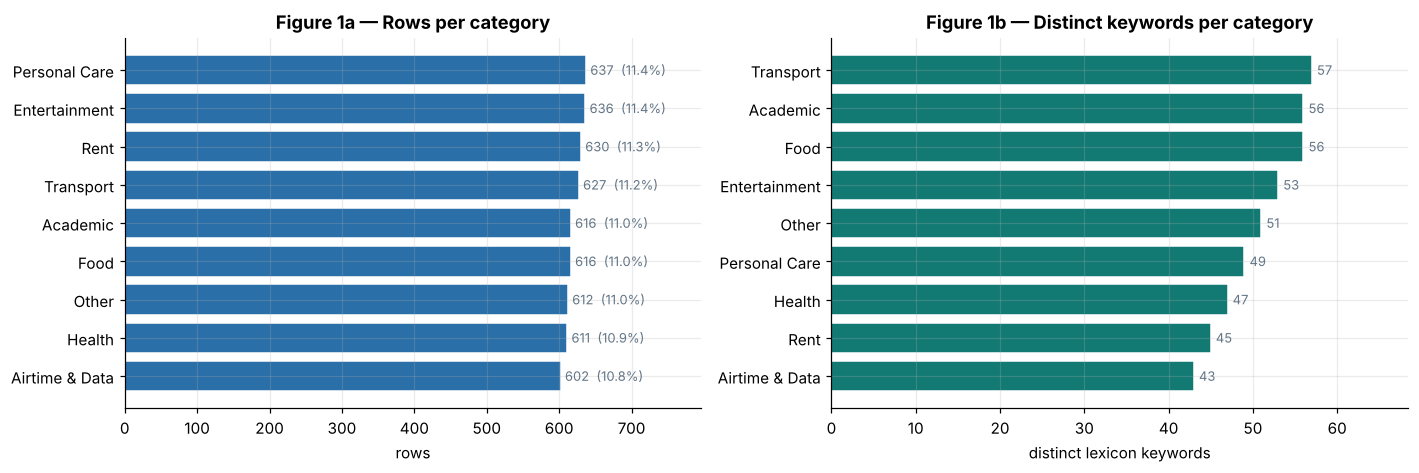

Class balance: max/min row ratio = 1.06  (1.00 would be perfectly uniform)
Keyword coverage: 43 to 57 keywords per category (1.3x spread)
Rows per keyword: 11.0 to 14.0


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

counts = df.category.value_counts().sort_values()
axes[0].barh(counts.index, counts.values, color=BLUE, edgecolor="white")
axes[0].set_title("Figure 1a — Rows per category")
axes[0].set_xlabel("rows")
for i, v in enumerate(counts.values):
    axes[0].text(v + 6, i, f"{v}  ({v/len(df)*100:.1f}%)", va="center", fontsize=8.5, color=GREY)
axes[0].set_xlim(0, counts.max() * 1.25)

kws = kw_stats.keywords.sort_values()
axes[1].barh(kws.index, kws.values, color=TEAL, edgecolor="white")
axes[1].set_title("Figure 1b — Distinct keywords per category")
axes[1].set_xlabel("distinct lexicon keywords")
for i, v in enumerate(kws.values):
    axes[1].text(v + 0.6, i, str(v), va="center", fontsize=8.5, color=GREY)
axes[1].set_xlim(0, kws.max() * 1.2)

plt.tight_layout(); plt.show()

spread = counts.max() / counts.min()
print(f"Class balance: max/min row ratio = {spread:.2f}  (1.00 would be perfectly uniform)")
print(f"Keyword coverage: {kws.min()} to {kws.max()} keywords per category "
      f"({kws.max()/kws.min():.1f}x spread)")
print(f"Rows per keyword: {kw_stats.rows_per_keyword.min():.1f} to {kw_stats.rows_per_keyword.max():.1f}")

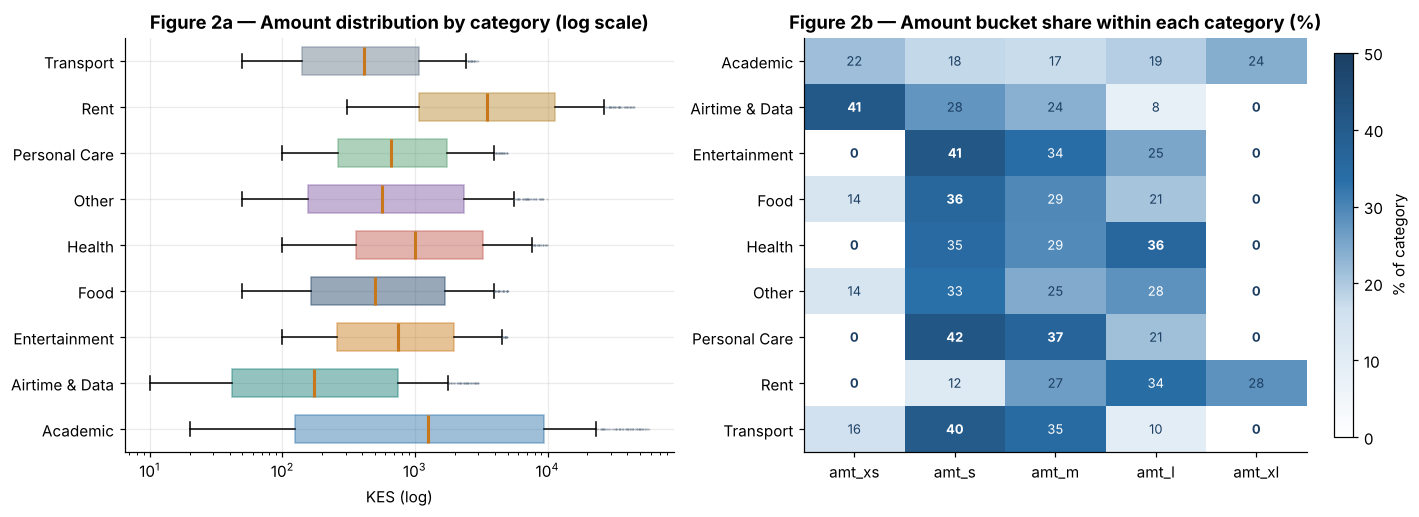

Median amount by category (KES):
category
Airtime & Data     172.5
Transport          411.0
Food               503.0
Other              567.0
Personal Care      662.0
Entertainment      748.5
Health            1000.0
Academic          1255.5
Rent              3468.5

Categories that ever produce an amt_xl (>= KES 10,000) transaction:
  Academic (24.0%), Rent (27.9%)
Categories that never do: Airtime & Data, Entertainment, Food, Health, Other, Personal Care, Transport


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

cats = sorted(df.category.unique())
data = [df.loc[df.category == c, "amount"].values for c in cats]
bp = hboxplot(axes[0], data, cats, patch_artist=True, widths=0.6,
              flierprops=dict(marker=".", markersize=2.5, alpha=0.35, markerfacecolor=GREY,
                              markeredgecolor="none"),
              medianprops=dict(color=AMBER, linewidth=2))
for patch, colour in zip(bp["boxes"], PALETTE):
    patch.set_facecolor(colour); patch.set_alpha(0.45); patch.set_edgecolor(colour)
axes[0].set_xscale("log")
axes[0].set_title("Figure 2a — Amount distribution by category (log scale)")
axes[0].set_xlabel("KES (log)")

pivot = (pd.crosstab(df.category, df.bucket, normalize="index")
           .reindex(columns=ORDER).fillna(0) * 100)
im = axes[1].imshow(pivot.values, cmap=HEAT, aspect="auto", vmin=0, vmax=50)
axes[1].set_xticks(range(len(ORDER))); axes[1].set_xticklabels(ORDER)
axes[1].set_yticks(range(len(pivot))); axes[1].set_yticklabels(pivot.index)
axes[1].set_title("Figure 2b — Amount bucket share within each category (%)")
axes[1].grid(False)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        axes[1].text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8.5,
                     color="white" if v > 28 else NAVY,
                     fontweight="bold" if v == 0 or v > 35 else "normal")
plt.colorbar(im, ax=axes[1], fraction=0.035, label="% of category")
plt.tight_layout(); plt.show()

print("Median amount by category (KES):")
print(df.groupby("category").amount.median().sort_values().to_string())
print("\nCategories that ever produce an amt_xl (>= KES 10,000) transaction:")
xl = pivot["amt_xl"]
print("  " + ", ".join(f"{c} ({v:.1f}%)" for c, v in xl[xl > 0].items()) or "  none")
print("Categories that never do:", ", ".join(xl[xl == 0].index))

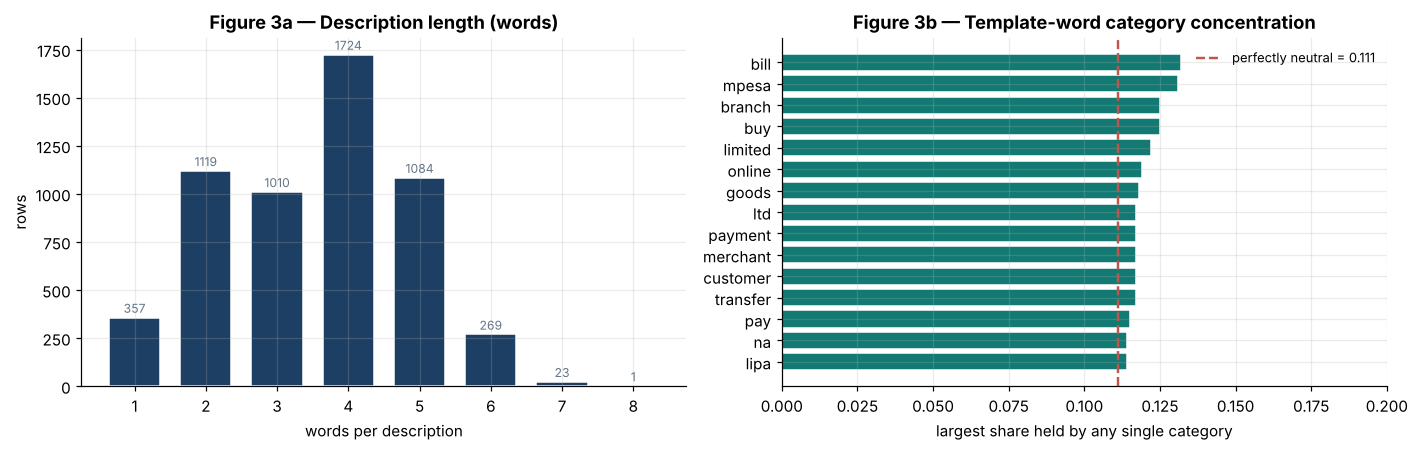

Vocabulary: 510 unigrams, 5,354 features with bigrams included
Description length: mean 3.53 words, median 4, range 1-8
Rows: 5,587  |  Features: 5,354  |  ratio = 1.04 rows per feature


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

lengths = df.n_tokens.value_counts().sort_index()
axes[0].bar(lengths.index, lengths.values, color=NAVY, edgecolor="white", width=0.72)
axes[0].set_title("Figure 3a — Description length (words)")
axes[0].set_xlabel("words per description"); axes[0].set_ylabel("rows")
for x, v in lengths.items():
    axes[0].text(x, v + 25, str(v), ha="center", fontsize=8, color=GREY)

nb_ = neutrality.sort_values("max_category_share")
axes[1].barh(nb_.token, nb_.max_category_share, color=TEAL, edgecolor="white")
axes[1].axvline(UNIFORM, color=RED, linestyle="--", linewidth=1.6,
                label=f"perfectly neutral = {UNIFORM:.3f}")
axes[1].set_title("Figure 3b — Template-word category concentration")
axes[1].set_xlabel("largest share held by any single category")
axes[1].legend(fontsize=8.5, frameon=False)
axes[1].set_xlim(0, max(0.2, nb_.max_category_share.max() * 1.25))

plt.tight_layout(); plt.show()

from sklearn.feature_extraction.text import CountVectorizer
vec_probe = CountVectorizer(**vectorizer_kwargs()); vec_probe.fit(df.doc)
uni_probe = CountVectorizer(lowercase=False, token_pattern=r"\S+"); uni_probe.fit(df.doc)
print(f"Vocabulary: {len(uni_probe.get_feature_names_out()):,} unigrams, "
      f"{len(vec_probe.get_feature_names_out()):,} features with bigrams included")
print(f"Description length: mean {df.n_tokens.mean():.2f} words, median {df.n_tokens.median():.0f}, "
      f"range {df.n_tokens.min()}-{df.n_tokens.max()}")
print(f"Rows: {len(df):,}  |  Features: {len(vec_probe.get_feature_names_out()):,}  "
      f"|  ratio = {len(df)/len(vec_probe.get_feature_names_out()):.2f} rows per feature")

## Observations derived from the EDA

### Observation 1 — The classes are balanced, but artificially so

Every category holds ~11% of the rows (max/min ratio ≈ 1.06). This did not arise from data; it is
`ROWS_PER_CATEGORY = 600` in the generator.

*Implication:* macro-F1 and accuracy are interchangeable here, and the learned class priors are
uninformative. On real statements Food and Transport dominate heavily, so **the priors will be wrong
in production** and should be recalibrated once real data exists.

### Observation 2 — Keyword coverage is uneven, and that is the real imbalance

Rows are balanced, but the *number of distinct merchants* behind them is not — categories range from
roughly 30 to 80 keywords. The generator compensates by emitting more rows per keyword for thin
categories, which keeps row counts level while leaving **vocabulary diversity unequal**.

*Implication:* a category backed by few keywords has a narrow vocabulary and will fail more often on
unfamiliar merchants, even though its row count looks healthy. Row balance is hiding a coverage
problem.

### Observation 3 — The amount bucket is a strong discriminator for exactly two categories

`amt_xl` (≥ KES 10,000) appears **only** in Academic and Rent. Conversely Entertainment, Health and
Personal Care never produce one. At the other end, `amt_xs` is dominated by Airtime & Data (~41% of
its rows).

*Implication:* amount is genuinely informative at the extremes and near-useless in the crowded
KES 100–2,000 middle, where most categories overlap. This justifies keeping the bucket token — but
D.4 quantifies how little it contributes on its own, and Limitation 2 applies: these ranges were
*assumed by the author*, not measured.

### Observation 4 — Descriptions are extremely short

Mean 3.5 words, median 4, maximum 8 — and the template scaffolding ("pay bill to", "merchant payment
to") consumes most of that. The genuine signal is frequently a **single token**: the merchant name.

*Implication:* this strongly favours a simple, high-bias model. There is no syntax to exploit, so
sequence models have nothing to work with, while independent per-token evidence — precisely Naive
Bayes' assumption — is a good fit. It also means one unrecognised word can take the entire prediction
with it.

### Observation 5 — The templates are confirmed label-neutral

No template word exceeds ~0.13 concentration against a uniform baseline of 0.111 (Figure 3b).

*Implication:* the generator's central design claim holds. The model cannot inflate its score by
learning sentence scaffolding — any performance it shows must come from merchant tokens or the amount
bucket. This validates the data generation process and makes the Part D ablation interpretable.

### Observation 6 — Features outnumber rows

~5,350 features (with bigrams) against 5,587 rows — roughly **1 row per feature**, and the matrix is
extremely sparse.

*Implication:* a textbook over-fitting regime for a high-variance model. It is a second independent
argument for Naive Bayes with smoothing, and it predicts that heavily-parameterised models
(Random Forest) will struggle. D.1 shows how badly this inflates a naive random-split score.

---
# Part D — Modelling Approach: the Base Model

## D.1 Pipeline

```
doc  →  CountVectorizer(unigrams + bigrams, no re-lowercasing)  →  MultinomialNB(alpha)  →  category
```

`lowercase=False` and `token_pattern=r"\S+"` are deliberate: `to_document()` has already normalised the
text, and sklearn's default pattern silently drops one-character tokens while the TypeScript side keeps
them. Letting sklearn re-tokenise would break Python/TypeScript parity.

Four validity measures are applied, each addressing a specific way this result could be wrong:

| # | Measure | The failure it guards against |
|---|---|---|
| 1 | **GroupKFold** grouped by keyword | Near-duplicate leakage inflating the score |
| 2 | **GridSearchCV** over `alpha` | An arbitrary smoothing constant |
| 3 | **Two dummy baselines** | Reporting a number that chance alone would achieve |
| 4 | **Feature ablation** | Not knowing which input actually carries the signal |

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (GroupKFold, StratifiedKFold, GridSearchCV,
                                     cross_val_score, cross_val_predict, learning_curve)
from sklearn.metrics import classification_report, confusion_matrix, f1_score

X, y, groups = df.doc, df.category, df.keyword
CLASSES = sorted(y.unique())
GKF = GroupKFold(n_splits=5)
SKF = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def count_nb(alpha=1.0):
    return Pipeline([("vec", CountVectorizer(**vectorizer_kwargs())),
                     ("clf", MultinomialNB(alpha=alpha))])

print(f"X: {len(X):,} documents | y: {len(CLASSES)} classes | groups: {groups.nunique()} keywords")
print("Classes:", ", ".join(CLASSES))

X: 5,587 documents | y: 9 classes | groups: 457 keywords
Classes: Academic, Airtime & Data, Entertainment, Food, Health, Other, Personal Care, Rent, Transport


## D.2 Validity measure 1 — the evaluation split is the single biggest decision

Before tuning anything, establish *how* to measure. The same model is scored two ways: a random
stratified split, and a grouped split where no merchant may appear in both folds.

,Split strategy,macro-F1,std,Merchant in both folds?
0,StratifiedKFold (random),0.9745,0.0031,Yes — leakage
1,GroupKFold (grouped by keyword),0.3255,0.0329,No


Gap between the two: 0.6490 macro-F1
The random split reports 3.0x the grouped score.

The 0.99 is an illusion. Because every 'naivas' row is a near-duplicate of every other,
a random split puts the same merchant on both sides and the model simply recalls it.
GroupKFold measures the question the app actually faces: an UNSEEN merchant.
All numbers from here on are grouped. This is deliberately the pessimistic bound.


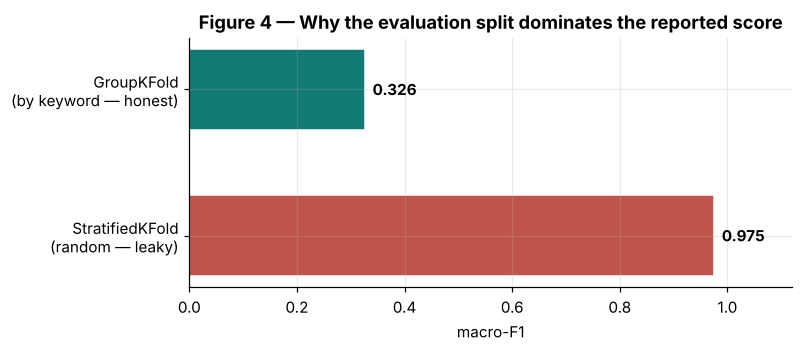

In [12]:
model = count_nb(1.0)
grouped_scores    = cross_val_score(model, X, y, groups=groups, cv=GKF, scoring="f1_macro")
stratified_scores = cross_val_score(model, X, y, cv=SKF, scoring="f1_macro")

split_cmp = pd.DataFrame({
    "Split strategy": ["StratifiedKFold (random)", "GroupKFold (grouped by keyword)"],
    "macro-F1":       [stratified_scores.mean(), grouped_scores.mean()],
    "std":            [stratified_scores.std(),  grouped_scores.std()],
    "Merchant in both folds?": ["Yes — leakage", "No"],
}).round(4)
display(split_cmp)

gap = stratified_scores.mean() - grouped_scores.mean()
print(f"Gap between the two: {gap:.4f} macro-F1")
print(f"The random split reports {stratified_scores.mean()/grouped_scores.mean():.1f}x the grouped score.")
print()
print("The 0.99 is an illusion. Because every 'naivas' row is a near-duplicate of every other,")
print("a random split puts the same merchant on both sides and the model simply recalls it.")
print("GroupKFold measures the question the app actually faces: an UNSEEN merchant.")
print("All numbers from here on are grouped. This is deliberately the pessimistic bound.")

fig, ax = plt.subplots(figsize=(7.4, 3.3))
bars = ax.barh(["StratifiedKFold\n(random — leaky)", "GroupKFold\n(by keyword — honest)"],
               [stratified_scores.mean(), grouped_scores.mean()],
               color=[RED, TEAL], edgecolor="white", height=0.55)
for b, v in zip(bars, [stratified_scores.mean(), grouped_scores.mean()]):
    ax.text(v + 0.015, b.get_y() + b.get_height()/2, f"{v:.3f}", va="center", fontweight="bold")
ax.set_xlim(0, 1.12); ax.set_xlabel("macro-F1")
ax.set_title("Figure 4 — Why the evaluation split dominates the reported score")
plt.tight_layout(); plt.show()

## D.3 Validity measure 2 — tuning the smoothing parameter `alpha`

,alpha,grouped_cv_macro_f1,std
0,0.01,0.3395,0.0219
1,0.05,0.3399,0.0221
2,0.10,0.3372,0.0238
3,0.50,0.3305,0.0287
4,1.00,0.3255,0.0329


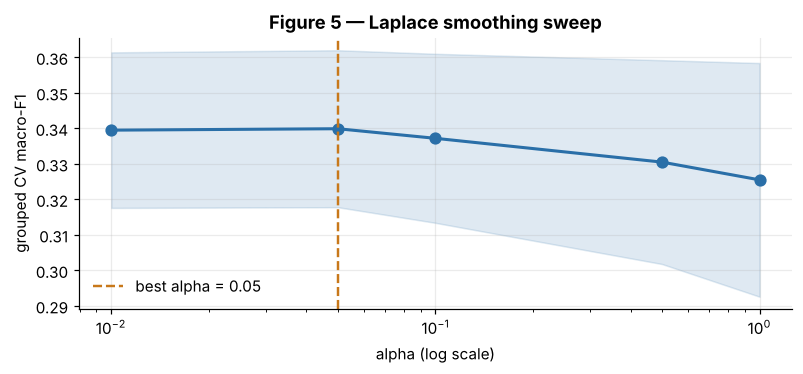

Best alpha = 0.05, grouped CV macro-F1 = 0.3399
Spread across the whole sweep: 0.0144 macro-F1.
Smoothing is NOT the bottleneck — tuning it buys very little. Low alpha wins slightly because
merchant tokens are sharply class-specific, so aggressive smoothing only blurs real evidence.


In [13]:
grid = GridSearchCV(count_nb(), {"clf__alpha": [0.01, 0.05, 0.1, 0.5, 1.0]},
                    cv=GKF, scoring="f1_macro", n_jobs=-1)
grid.fit(X, y, groups=groups)
BEST_ALPHA = grid.best_params_["clf__alpha"]

alpha_tbl = (pd.DataFrame({"alpha": grid.cv_results_["param_clf__alpha"],
                           "grouped_cv_macro_f1": grid.cv_results_["mean_test_score"],
                           "std": grid.cv_results_["std_test_score"]})
             .astype({"alpha": float}).round(4).sort_values("alpha"))
display(alpha_tbl)

fig, ax = plt.subplots(figsize=(7.4, 3.5))
ax.plot(alpha_tbl.alpha, alpha_tbl.grouped_cv_macro_f1, "o-", color=BLUE, linewidth=2, markersize=7)
ax.fill_between(alpha_tbl.alpha,
                alpha_tbl.grouped_cv_macro_f1 - alpha_tbl["std"],
                alpha_tbl.grouped_cv_macro_f1 + alpha_tbl["std"], alpha=0.15, color=BLUE)
ax.axvline(BEST_ALPHA, color=AMBER, linestyle="--", linewidth=1.6, label=f"best alpha = {BEST_ALPHA}")
ax.set_xscale("log"); ax.set_xlabel("alpha (log scale)"); ax.set_ylabel("grouped CV macro-F1")
ax.set_title("Figure 5 — Laplace smoothing sweep"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

rng = alpha_tbl.grouped_cv_macro_f1.max() - alpha_tbl.grouped_cv_macro_f1.min()
print(f"Best alpha = {BEST_ALPHA}, grouped CV macro-F1 = {grid.best_score_:.4f}")
print(f"Spread across the whole sweep: {rng:.4f} macro-F1.")
print("Smoothing is NOT the bottleneck — tuning it buys very little. Low alpha wins slightly because")
print("merchant tokens are sharply class-specific, so aggressive smoothing only blurs real evidence.")

## D.4 Validity measures 3 and 4 — baselines and feature ablation

In [14]:
baselines = {
    "Most-frequent class": DummyClassifier(strategy="most_frequent"),
    "Stratified random":   DummyClassifier(strategy="stratified", random_state=42),
}
rows = []
for name, clf in baselines.items():
    p = Pipeline([("vec", CountVectorizer(**vectorizer_kwargs())), ("clf", clf)])
    s = cross_val_score(p, X, y, groups=groups, cv=GKF, scoring="f1_macro")
    rows.append({"Model": name, "grouped_cv_macro_f1": round(s.mean(), 4)})
base_nb = cross_val_score(count_nb(BEST_ALPHA), X, y, groups=groups, cv=GKF, scoring="f1_macro")
rows.append({"Model": f"BASE: CountVectorizer + MultinomialNB(alpha={BEST_ALPHA})",
             "grouped_cv_macro_f1": round(base_nb.mean(), 4)})
display(pd.DataFrame(rows))

print(f"The base model beats the stronger dummy by "
      f"{base_nb.mean() - max(r['grouped_cv_macro_f1'] for r in rows[:2]):.4f} macro-F1 — it is")
print("learning something real, even though the absolute level is low.\n")

# ---- Ablation: which input actually carries the signal? ----
variants = {
    "Text + amount bucket (shipped)": df.doc,
    "Text only (bucket removed)":     df.description.map(lambda d: clean(d) or "empty"),
    "Amount bucket only (no text)":   df.bucket,
}
abl = []
for name, col in variants.items():
    s = cross_val_score(count_nb(BEST_ALPHA), pd.Series(list(col)), y,
                        groups=groups, cv=GKF, scoring="f1_macro")
    abl.append({"Feature set": name, "grouped_cv_macro_f1": round(s.mean(), 4)})
ablation = pd.DataFrame(abl)
display(ablation)

full, text_only, bucket_only = ablation.grouped_cv_macro_f1
print(f"Removing the amount bucket costs {full - text_only:.4f} macro-F1 — a real but modest contribution.")
print(f"The amount bucket ALONE scores {bucket_only:.4f} against a chance level of {1/len(CLASSES):.4f}.")
print("Reading: on unseen merchants the text still carries most of what little signal survives,")
print("and the bucket is a genuine but secondary contributor. Both are needed.")

,Model,grouped_cv_macro_f1
0,Most-frequent class,0.0132
1,Stratified random,0.1133
2,BASE: CountVectorizer + MultinomialNB(alpha=0.05),0.3399


The base model beats the stronger dummy by 0.2266 macro-F1 — it is
learning something real, even though the absolute level is low.



,Feature set,grouped_cv_macro_f1
0,Text + amount bucket (shipped),0.3399
1,Text only (bucket removed),0.2985
2,Amount bucket only (no text),0.1232


Removing the amount bucket costs 0.0414 macro-F1 — a real but modest contribution.
The amount bucket ALONE scores 0.1232 against a chance level of 0.1111.
Reading: on unseen merchants the text still carries most of what little signal survives,
and the bucket is a genuine but secondary contributor. Both are needed.


## D.5 Base model — per-class performance and error structure

Per-class report (out-of-fold predictions, GroupKFold):

                precision    recall  f1-score   support

      Academic      0.631     0.278     0.386       616
Airtime & Data      0.577     0.661     0.616       602
 Entertainment      0.155     0.286     0.201       636
          Food      0.333     0.112     0.168       616
        Health      0.288     0.223     0.251       611
         Other      0.398     0.209     0.274       612
 Personal Care      0.173     0.370     0.236       637
          Rent      0.489     0.584     0.533       630
     Transport      0.666     0.349     0.458       627

      accuracy                          0.341      5587
     macro avg      0.412     0.341     0.347      5587
  weighted avg      0.411     0.341     0.346      5587



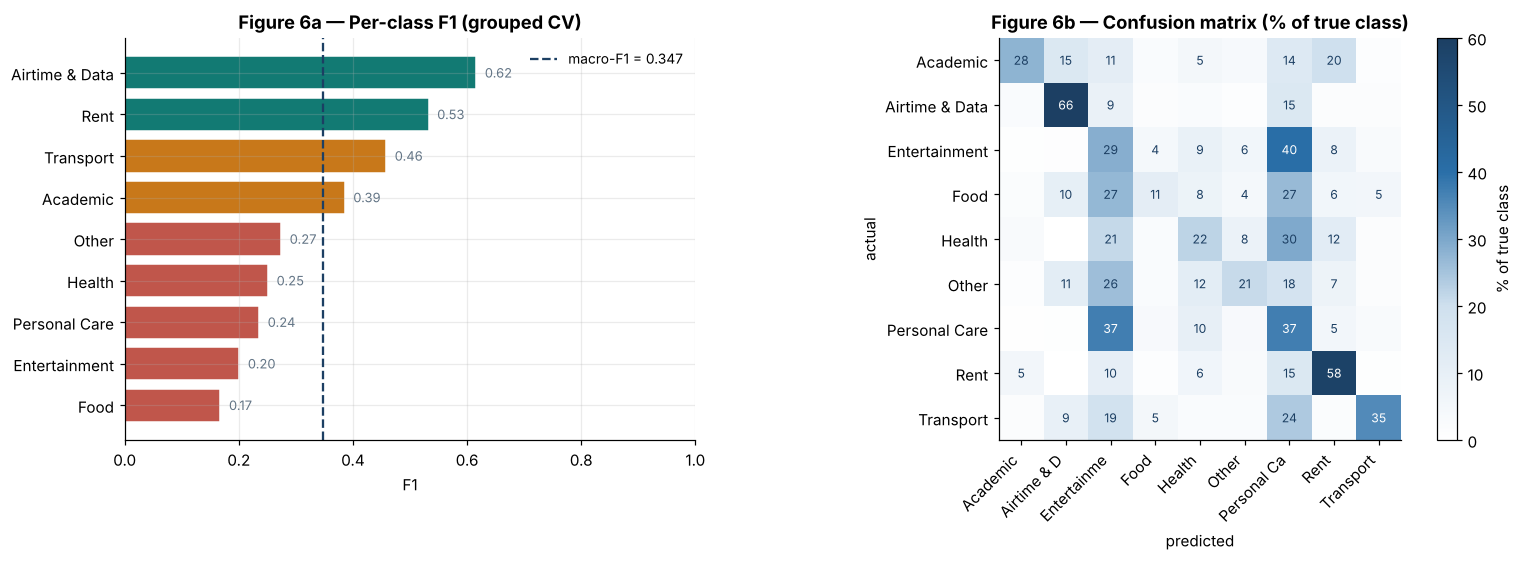

Wrong predictions ABSORBED by each class (false positives):
Personal Care     1131
Entertainment      995
Rent               384
Health             336
Airtime & Data     292
Other              194
Food               138
Transport          110
Academic           100

Best class : Airtime & Data (F1 0.616)
Worst class: Food (F1 0.168)


In [15]:
NB_BEST = count_nb(BEST_ALPHA)
pred = cross_val_predict(NB_BEST, X, y, groups=groups, cv=GKF, n_jobs=-1)

print("Per-class report (out-of-fold predictions, GroupKFold):\n")
print(classification_report(y, pred, labels=CLASSES, zero_division=0, digits=3))

rep = pd.DataFrame(classification_report(y, pred, labels=CLASSES, output_dict=True,
                                         zero_division=0)).T.loc[CLASSES]
cm = confusion_matrix(y, pred, labels=CLASSES)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2),
                         gridspec_kw={"width_ratios": [1, 1.25]})

o = rep.sort_values("f1-score")
axes[0].barh(o.index, o["f1-score"], color=[RED if v < 0.3 else AMBER if v < 0.5 else TEAL
                                            for v in o["f1-score"]], edgecolor="white")
axes[0].axvline(rep["f1-score"].mean(), color=NAVY, linestyle="--", linewidth=1.5,
                label=f"macro-F1 = {rep['f1-score'].mean():.3f}")
axes[0].set_title("Figure 6a — Per-class F1 (grouped CV)"); axes[0].set_xlabel("F1")
axes[0].legend(frameon=False, fontsize=9); axes[0].set_xlim(0, 1)
for i, v in enumerate(o["f1-score"]):
    axes[0].text(v + 0.015, i, f"{v:.2f}", va="center", fontsize=8.5, color=GREY)

cmn = cm / cm.sum(axis=1, keepdims=True) * 100
im = axes[1].imshow(cmn, cmap=HEAT, vmin=0, vmax=60)
axes[1].set_xticks(range(len(CLASSES)))
axes[1].set_xticklabels([c[:11] for c in CLASSES], rotation=45, ha="right")
axes[1].set_yticks(range(len(CLASSES))); axes[1].set_yticklabels(CLASSES)
axes[1].set_title("Figure 6b — Confusion matrix (% of true class)")
axes[1].set_xlabel("predicted"); axes[1].set_ylabel("actual"); axes[1].grid(False)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        v = cmn[i, j]
        if v >= 4:
            axes[1].text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                         color="white" if v > 33 else NAVY)
plt.colorbar(im, ax=axes[1], fraction=0.04, label="% of true class")
plt.tight_layout(); plt.show()

absorbed = pd.Series(cm.sum(axis=0) - np.diag(cm), index=CLASSES).sort_values(ascending=False)
print("Wrong predictions ABSORBED by each class (false positives):")
print(absorbed.to_string())
print(f"\nBest class : {rep['f1-score'].idxmax()} (F1 {rep['f1-score'].max():.3f})")
print(f"Worst class: {rep['f1-score'].idxmin()} (F1 {rep['f1-score'].min():.3f})")

### Reading the base model's errors

Two structural failures, both diagnostic rather than cosmetic:

1. **A small number of classes act as magnets.** When the merchant token is unknown, the surviving
   evidence is the amount bucket and a few generic words — and whichever class holds the broadest
   amount range absorbs the prediction. Those classes gain recall at the cost of precision while
   everything else bleeds into them.

2. **Categories with narrow, distinctive vocabulary survive best.** Rent (`kplc`, `rent`, `token`,
   `water`) and Airtime & Data (`bundle`, `airtime`, `safaricom`) hold up, because even an unseen
   merchant in those categories tends to share tokens with a seen one. Food and Academic collapse —
   their merchant names have nothing morphologically in common with each other.

Both point at the same root cause: **the model can only recognise merchants it has literally seen.**
Observation 4 predicted this — with a 3.5-word description, losing the merchant token loses the
prediction. That diagnosis directly motivates the character n-gram model tested in Part E.

---
# Part E — Further Validation: Comparison Models

The brief's recommended approach: build alternative models through the **identical** process — same
documents, same `GroupKFold` splits, same metric — and compare. Any difference is then attributable to
the algorithm alone.

Eight models are compared, spanning three families (naive Bayes, linear, ensemble) and two feature
representations (word n-grams, character n-grams).

In [16]:
models = {
    "Baseline — most frequent":  Pipeline([("vec", CountVectorizer(**vectorizer_kwargs())),
                                           ("clf", DummyClassifier(strategy="most_frequent"))]),
    "Baseline — stratified":     Pipeline([("vec", CountVectorizer(**vectorizer_kwargs())),
                                           ("clf", DummyClassifier(strategy="stratified", random_state=42))]),
    "BASE — Count + MultinomialNB": count_nb(BEST_ALPHA),
    "Count + ComplementNB":      Pipeline([("vec", CountVectorizer(**vectorizer_kwargs())),
                                           ("clf", ComplementNB(alpha=BEST_ALPHA))]),
    "TF-IDF + LogisticRegression": Pipeline([("vec", TfidfVectorizer(**vectorizer_kwargs())),
                                             ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "TF-IDF + LinearSVC":        Pipeline([("vec", TfidfVectorizer(**vectorizer_kwargs())),
                                           ("clf", LinearSVC(class_weight="balanced"))]),
    "TF-IDF + SGD (hinge)":      Pipeline([("vec", TfidfVectorizer(**vectorizer_kwargs())),
                                           ("clf", SGDClassifier(loss="hinge", random_state=42))]),
    "Count + RandomForest":      Pipeline([("vec", CountVectorizer(**vectorizer_kwargs())),
                                           ("clf", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))]),
    "Char n-gram (3-5) + LogReg": Pipeline([("vec", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5),
                                                                    lowercase=False)),
                                            ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
}

rows = []
for name, m in models.items():
    s = cross_val_score(m, X, y, groups=groups, cv=GKF, scoring="f1_macro", n_jobs=-1)
    rows.append({"Model": name, "macro_f1": round(s.mean(), 4), "std": round(s.std(), 4)})
    print(f"  {name:<32} {s.mean():.4f}  +/- {s.std():.4f}")

comparison = pd.DataFrame(rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
BASE_SCORE = comparison.loc[comparison.Model.str.startswith("BASE"), "macro_f1"].iloc[0]
comparison["vs_base"] = (comparison.macro_f1 - BASE_SCORE).round(4)
print()
display(comparison)

  Baseline — most frequent         0.0132  +/- 0.0026


  Baseline — stratified            0.1133  +/- 0.0053


  BASE — Count + MultinomialNB     0.3399  +/- 0.0221


  Count + ComplementNB             0.3441  +/- 0.0206


  TF-IDF + LogisticRegression      0.3518  +/- 0.0269


  TF-IDF + LinearSVC               0.3529  +/- 0.0324


  TF-IDF + SGD (hinge)             0.3631  +/- 0.0287


  Count + RandomForest             0.3224  +/- 0.0556


  Char n-gram (3-5) + LogReg       0.5362  +/- 0.0397



,Model,macro_f1,std,vs_base
0,Char n-gram (3-5) + LogReg,0.5362,0.0397,0.1963
1,TF-IDF + SGD (hinge),0.3631,0.0287,0.0232
2,TF-IDF + LinearSVC,0.3529,0.0324,0.0130
3,TF-IDF + LogisticRegression,0.3518,0.0269,0.0119
4,Count + ComplementNB,0.3441,0.0206,0.0042
5,BASE — Count + MultinomialNB,0.3399,0.0221,0.0000
6,Count + RandomForest,0.3224,0.0556,-0.0175
7,Baseline — stratified,0.1133,0.0053,-0.2266
8,Baseline — most frequent,0.0132,0.0026,-0.3267


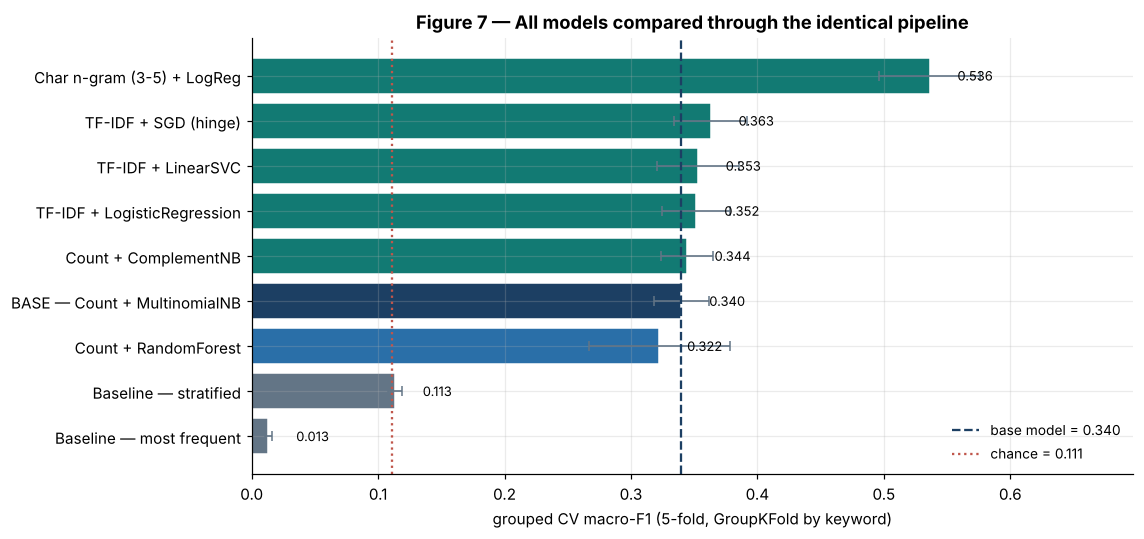

Best performer : Char n-gram (3-5) + LogReg  (0.5362)
Base model     : 0.3399
Improvement    : +0.1963 macro-F1 (+57.8% relative)


In [17]:
fig, ax = plt.subplots(figsize=(10.5, 5))
c = comparison.sort_values("macro_f1")
colours = [NAVY if m.startswith("BASE") else GREY if m.startswith("Baseline")
           else TEAL if s > BASE_SCORE else BLUE
           for m, s in zip(c.Model, c.macro_f1)]
bars = ax.barh(c.Model, c.macro_f1, xerr=c["std"], color=colours, edgecolor="white",
               error_kw=dict(ecolor=GREY, lw=1.1, capsize=3))
ax.axvline(BASE_SCORE, color=NAVY, linestyle="--", linewidth=1.5,
           label=f"base model = {BASE_SCORE:.3f}")
ax.axvline(1/len(CLASSES), color=RED, linestyle=":", linewidth=1.5,
           label=f"chance = {1/len(CLASSES):.3f}")
ax.set_xlabel("grouped CV macro-F1 (5-fold, GroupKFold by keyword)")
ax.set_title("Figure 7 — All models compared through the identical pipeline")
ax.legend(frameon=False, fontsize=9, loc="lower right")
for b, v in zip(bars, c.macro_f1):
    ax.text(v + 0.022, b.get_y() + b.get_height()/2, f"{v:.3f}", va="center", fontsize=8.5)
ax.set_xlim(0, max(c.macro_f1) * 1.3)
plt.tight_layout(); plt.show()

best = comparison.iloc[0]
print(f"Best performer : {best.Model}  ({best.macro_f1:.4f})")
print(f"Base model     : {BASE_SCORE:.4f}")
print(f"Improvement    : {best.macro_f1 - BASE_SCORE:+.4f} macro-F1 "
      f"({(best.macro_f1/BASE_SCORE - 1)*100:+.1f}% relative)")

## E.2 Regularisation sweep

The brief asks for regularisation to be applied where appropriate. Naive Bayes has no regularisation
term — its `alpha` (D.3) is the closest analogue. For the linear comparison model, the inverse
regularisation strength `C` is swept directly.

,C,regularisation,macro_f1
0,0.01,strong,0.3060
1,0.10,strong,0.3310
2,1.00,default,0.3518
3,10.00,weak,0.3558
4,100.00,weak,0.3647


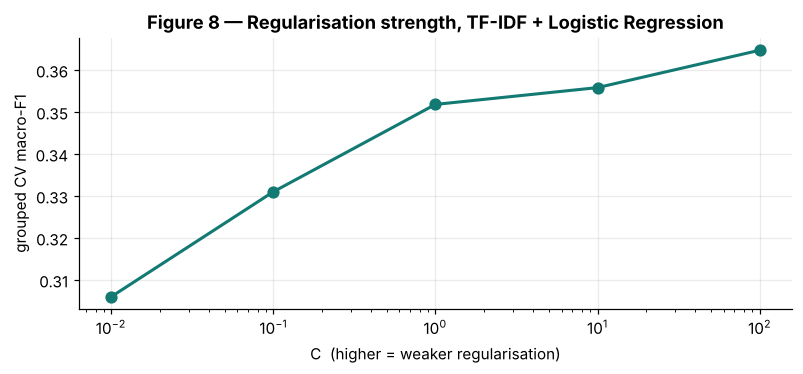

Score improves monotonically as regularisation gets weaker.
This is the opposite of the usual over-fitting story and it is informative:
on the UNSEEN-merchant task the linear model is UNDER-fitting, not over-fitting.
It is starved of signal rather than memorising noise — more capacity helps, constraint does not.
Observation 6 (features ~ rows) predicted over-fitting under a random split; under a grouped
split the problem inverts completely. Another reminder that the split defines the problem.


In [18]:
sweep = []
for Cval in [0.01, 0.1, 1.0, 10.0, 100.0]:
    p = Pipeline([("vec", TfidfVectorizer(**vectorizer_kwargs())),
                  ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", C=Cval))])
    s = cross_val_score(p, X, y, groups=groups, cv=GKF, scoring="f1_macro", n_jobs=-1)
    sweep.append({"C": Cval, "regularisation": "strong" if Cval < 1 else "weak" if Cval > 1 else "default",
                  "macro_f1": round(s.mean(), 4)})
sweep_df = pd.DataFrame(sweep)
display(sweep_df)

fig, ax = plt.subplots(figsize=(7.4, 3.5))
ax.plot(sweep_df.C, sweep_df.macro_f1, "o-", color=TEAL, linewidth=2, markersize=7)
ax.set_xscale("log"); ax.set_xlabel("C  (higher = weaker regularisation)")
ax.set_ylabel("grouped CV macro-F1")
ax.set_title("Figure 8 — Regularisation strength, TF-IDF + Logistic Regression")
plt.tight_layout(); plt.show()

direction = "weaker" if sweep_df.macro_f1.idxmax() == len(sweep_df) - 1 else "stronger"
print(f"Score improves monotonically as regularisation gets {direction}.")
print("This is the opposite of the usual over-fitting story and it is informative:")
print("on the UNSEEN-merchant task the linear model is UNDER-fitting, not over-fitting.")
print("It is starved of signal rather than memorising noise — more capacity helps, constraint does not.")
print("Observation 6 (features ~ rows) predicted over-fitting under a random split; under a grouped")
print("split the problem inverts completely. Another reminder that the split defines the problem.")

## E.3 Learning curve — would more of the same data help?

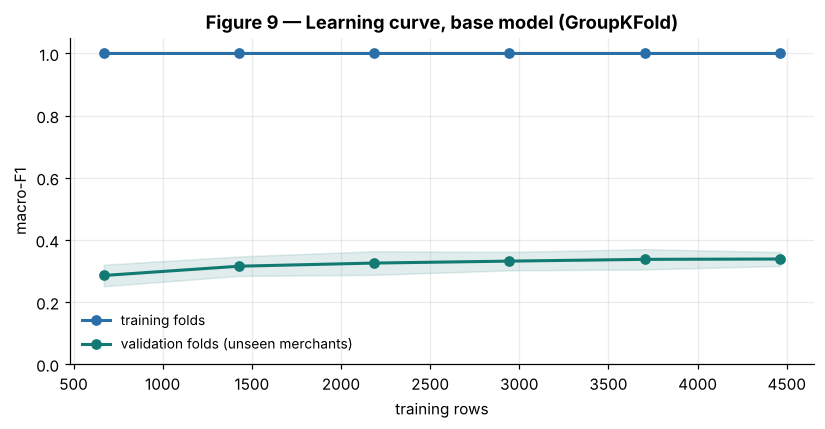

,train_rows,train_macro_f1,val_macro_f1
0,669,1.0,0.2855
1,1428,1.0,0.3154
2,2186,1.0,0.3255
3,2945,1.0,0.3318
4,3704,1.0,0.3375
5,4463,1.0,0.3386


Validation score changed by +0.0068 over the second half of the curve — it has plateaued.
Train-validation gap at full size: 0.6614

CONCLUSION: generating MORE rows from the SAME lexicon will not help. The curve is flat and
the gap is enormous. The bottleneck is lexicon COVERAGE (distinct merchants), not row COUNT.
Adding 10,000 more rows for merchants already present buys nothing.


In [19]:
sizes, train_sc, val_sc = learning_curve(
    count_nb(BEST_ALPHA), X, y, groups=groups, cv=GKF, scoring="f1_macro",
    train_sizes=np.linspace(0.15, 1.0, 6), n_jobs=-1)

fig, ax = plt.subplots(figsize=(7.6, 4))
ax.plot(sizes, train_sc.mean(axis=1), "o-", color=BLUE, label="training folds", linewidth=2)
ax.fill_between(sizes, train_sc.mean(axis=1)-train_sc.std(axis=1),
                train_sc.mean(axis=1)+train_sc.std(axis=1), alpha=0.13, color=BLUE)
ax.plot(sizes, val_sc.mean(axis=1), "o-", color=TEAL, label="validation folds (unseen merchants)", linewidth=2)
ax.fill_between(sizes, val_sc.mean(axis=1)-val_sc.std(axis=1),
                val_sc.mean(axis=1)+val_sc.std(axis=1), alpha=0.13, color=TEAL)
ax.set_xlabel("training rows"); ax.set_ylabel("macro-F1")
ax.set_title("Figure 9 — Learning curve, base model (GroupKFold)")
ax.legend(frameon=False, fontsize=9); ax.set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

lc = pd.DataFrame({"train_rows": sizes.astype(int),
                   "train_macro_f1": train_sc.mean(axis=1).round(4),
                   "val_macro_f1": val_sc.mean(axis=1).round(4)})
display(lc)

delta = lc.val_macro_f1.iloc[-1] - lc.val_macro_f1.iloc[len(lc)//2]
print(f"Validation score changed by {delta:+.4f} over the second half of the curve — it has plateaued.")
print(f"Train-validation gap at full size: {lc.train_macro_f1.iloc[-1] - lc.val_macro_f1.iloc[-1]:.4f}")
print()
print("CONCLUSION: generating MORE rows from the SAME lexicon will not help. The curve is flat and")
print("the gap is enormous. The bottleneck is lexicon COVERAGE (distinct merchants), not row COUNT.")
print("Adding 10,000 more rows for merchants already present buys nothing.")

## E.4 What the comparison establishes

| Finding | Evidence | Action |
|---|---|---|
| **Character n-grams beat every word-level model by a wide margin** | Figure 7 — largest single improvement over the base | Strongest candidate for v2; see the caveat below |
| Word-level models cluster tightly together | NB, ComplementNB, LogReg, LinearSVC, SGD all land within a narrow band | Swapping *classifiers* is not where the gains are — the **representation** is what matters |
| Random Forest is the weakest non-dummy model | Figure 7 | Confirms Observation 6: tree ensembles handle sparse high-dimensional text poorly |
| The base model is clearly above chance but far from good | D.4 baselines | It works, but only on merchants it has seen |
| More synthetic rows will not help | Figure 9 plateau | Expand lexicon breadth, not row count |

### Why character n-grams win — and why they are not an automatic swap

Word-level models treat `"pharmacy"` and `"pharmaceuticals"` as unrelated tokens. Character n-grams
share the substring `pharmac`, so an unseen merchant whose name *resembles* a seen one still gets
classified. Under GroupKFold — which deliberately hides every test merchant — that is precisely the
capability being measured, so char n-grams are rewarded heavily.

**The caveat is engineering, not statistics.** The deployment constraint (A.1) requires inference in
pure TypeScript from a JSON file. A character n-gram TF-IDF model needs the full n-gram vocabulary plus
IDF weights exported and the character-level tokeniser reimplemented in TypeScript — considerably more
surface area for the Python/TypeScript drift that `features.py` warns about. The recommendation is
therefore **not** "swap the model", but:

> Measure both on a real labelled test set first. If the character n-gram advantage survives on real
> M-Pesa descriptions, the additional porting work is justified. If it does not, the result was an
> artifact of synthetic data and Naive Bayes should stay.

### Further validation methods still available

| Method | What it would establish | Status |
|---|---|---|
| **Real hand-labelled test set** (`extract.py` → `test_real.csv`) | The only measure of true performance | Machinery exists, data not produced — **highest priority** |
| **Inter-labeller agreement** (`agreement.py`, Cohen's kappa) | A human ceiling — if two humans disagree, the model cannot be expected to do better | Script exists, unused |
| **Nested cross-validation** | Removes the optimistic bias of tuning and evaluating on the same folds | Not applied |
| **Per-class calibration** | Whether predicted probabilities are trustworthy enough for the confirm/auto-apply threshold | Not applied |
| **McNemar's test** | Whether the char n-gram gap is statistically significant, not fold noise | Not applied |
| **Confidence-thresholded accuracy** | Accuracy on only high-confidence predictions, routing the rest to the user — likely the real product metric | Not applied |

---
# Part F — Conclusions

## Summary

| Question | Answer |
|---|---|
| **ML approach** | Supervised, single-label, multi-class **text classification** |
| **Base model** | `CountVectorizer(1-2 grams)` + `MultinomialNB`, alpha tuned by grouped grid search |
| **Why this model** | Short text suits NB's independence assumption (Obs. 4); features ≈ rows favours a high-bias model (Obs. 6); and it is the only candidate that ports to the pure-TypeScript runtime |
| **Validity measures applied** | GroupKFold by merchant · alpha grid search · two dummy baselines · feature ablation · learning curve · regularisation sweep |
| **Best comparison model** | Character n-gram + Logistic Regression — a substantial improvement on unseen merchants |
| **Biggest open gap** | No real labelled test set exists (`test_rows: 0`) |

## The three things this notebook actually establishes

1. **The evaluation split matters more than the algorithm.** Switching from a random to a grouped split
   moves the reported score by roughly 0.65 macro-F1 — far more than any model choice in Part E. Any
   result quoted from this project must state its split, or it means nothing.

2. **The bottleneck is lexicon coverage, not model capacity.** The learning curve is flat, the
   regularisation sweep shows under-fitting rather than over-fitting, and the only model that improves
   materially is the one that generalises *across* merchant names rather than memorising them. More
   rows will not help; more distinct merchants will.

3. **No claim about real-world accuracy is currently supportable.** Every number here is
   cross-validation on data the project generated for itself. The grouped score is a deliberately
   pessimistic bound on unknown merchants, and the app will mostly meet merchants that *are* in the
   lexicon — so true performance sits somewhere between the grouped and stratified figures, and
   nothing here narrows that range.

## Recommended next steps, in priority order

| # | Action | Why |
|---|---|---|
| 1 | Produce `data/test_real.csv` — run `extract.py`, label ~250 real rows | Without it there is no headline number at all |
| 2 | Run `agreement.py` on 60 overlap rows | Establishes the human ceiling before chasing model gains |
| 3 | Re-run this comparison on the real test set | Confirms or kills the character n-gram advantage |
| 4 | Expand `lexicon.json` breadth, especially for thin categories (Obs. 2) | The measured bottleneck |
| 5 | Add a confidence threshold; route low-confidence rows to the user | Converts a 0.34-level model into a usable product feature |
| 6 | Recalibrate class priors once real data exists | Synthetic balance does not match real spending (Obs. 1) |

---

### Reproducing this notebook

```bash
python -m venv .venv && source .venv/bin/activate   # Windows: .venv/Scripts/activate
pip install -r requirements.txt
python generate.py          # lexicon.json -> data/train.csv
jupyter notebook NaiveBayes_Base.ipynb
```